<a href="https://colab.research.google.com/github/manal-0603/LAB_CLIP_LLaVA_Full_Lab_Statement/blob/main/LAB_CLIP_LLaVA_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

> **Completed version.** Every *STUDENT TASK* cell has been implemented and executed on **Google Colab** (GPU runtime: *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*). Written answers to questions Q1–Q36 follow each exercise.
> Images come from Wikimedia Commons (see `images/CREDITS.json`) and were labelled by hand. On Colab, the setup cell below
> either unzips an uploaded `images.zip` (identical images → identical numbers) or re-downloads them from Wikimedia Commons.
>
> To keep the lab runnable on a free Colab GPU (and even on CPU), the LLaVA part uses the lightweight, LLaVA-compatible checkpoint
> `llava-hf/llava-interleave-qwen-0.5b-hf` (CLIP/SigLIP vision encoder + projector + Qwen-2 0.5B language model, ~0.9 B parameters),
> which uses exactly the same `LlavaForConditionalGeneration` architecture and API as `llava-hf/llava-1.5-7b-hf`.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [1]:
# Run this cell first. (On Google Colab torch/torchvision are pre-installed; we only make sure Transformers is recent.)
%pip install -q -U "transformers>=4.57" accelerate pillow matplotlib pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 87.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 87.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0

In [2]:
# ---- Dataset setup (needed on Google Colab / a fresh machine) ----
# Priority: (1) an existing images/ folder, (2) images.zip uploaded next to the notebook (exactly the images used for the
# reference results), (3) re-download of the same 46 pictures from Wikimedia Commons (sizes may differ slightly).
import os, zipfile, urllib.request, urllib.parse, time

IMAGE_FILES = {
 "cat_1.jpg": "File:Cat Iran.jpg",
 "cat_2.jpg": "File:Domestic shorthair cat portrait in grass.jpg",
 "cat_3.jpg": "File:Domestic cat in natural environment.jpg",
 "cat_4.jpg": "File:Gato comun atigrado 02.jpg",
 "dog_1.jpg": "File:Official Portrait of Buddy the Dog - DPLA - 8bb24feae78ce1f060addb5682fc48e6.jpg",
 "dog_2.jpg": "File:Macy Kate.jpg",
 "dog_3.jpg": "File:200318-F-YA239-780 - PAWS Dog Missed by Spangdahlem Air Base.jpg",
 "dog_4_painting.jpg": "File:\"Man with Dog\", 1923 self-portrait by Otis Oldfield.jpg",
 "car_1.jpg": "File:1973 Lincoln Continental Town Car sedan (12404237654).jpg",
 "car_2.jpg": "File:1977 Lincoln Continental Town Car sedan (8453061612).jpg",
 "car_3.jpg": "File:1977 Lincoln Continental Town Car sedan (8453059332).jpg",
 "airplane_1.jpg": "File:Sukhoi SuperJet 100 (5114478300).jpg",
 "airplane_2.jpg": "File:White and Red Qantas Airplane Fly High Under Blue and White Clouds.jpeg",
 "airplane_3.jpg": "File:Jiutian Flying Club Sunward SA60L Aurora B-12LH.jpg",
 "horse_1_oldphoto.jpg": "File:Cowgirl Standing with Horse (4666519521).jpg",
 "horse_2_engraving.jpg": "File:A plough horse standing in a field with a farm house in the Wellcome V0021148ER.jpg",
 "horse_3_skeleton.jpg": "File:Skeleton of horse. Standing LOC 13624693083.jpg",
 "bird_1.jpg": "File:Cheer Up (17021538767).jpg",
 "bird_2.jpg": "File:A small songbird (perhaps a waxwing) perched in a tree (51770760540).jpg",
 "bird_3_silhouette.jpg": "File:DSG6553-1 - A lone songbird perched on the topmost twiglet.jpg",
 "football_1.jpg": "File:Football in Bloomington, Indiana, 1995.jpg",
 "football_2.jpg": "File:2 guys playing soccer - good.jpg",
 "football_3.jpg": "File:III MEF Band performs at exhibition soccer match between Kobe Leonessa, UCLA 140323-M-PJ295-001.jpg",
 "basketball_1.jpg": "File:Bryant Bulldog basketball player Earl Timberlake.jpg",
 "basketball_2.jpg": "File:2024-25 Boston University basketball players before a game.jpg",
 "building_1.jpg": "File:Gray skyscraper facade (Unsplash).jpg",
 "building_2.jpg": "File:Skyscraper And Angled Building, CBD.jpg",
 "building_3.jpg": "File:Tiled skyscraper facade (Unsplash).jpg",
 "landscape_1.jpg": "File:Mountains in snow, Mountain lake, Chola Valley, Nepal, Himalayas.jpg",
 "landscape_2.jpg": "File:Zagedan Lakes, Mountain cirque, Caucasus Mountains.jpg",
 "landscape_3.jpg": "File:Ergaki, Mountain lake Skazka, Rock formations, Sayan Mountains, Russia.jpg",
 "food_1_pizza_slice.jpg": "File:Giorgio's Pizza - June 2022 - Sarah Stierch 08.jpg",
 "food_2_pizza.jpg": "File:Village Pizza Atlanta.jpg",
 "people_1_group.jpg": "File:Photographer taking a group photograph of smiling students in front of the Tokyo station, Marunouchi, Japan.jpg",
 "people_2_portrait.jpg": "File:Kalpana Chawla, NASA photo portrait in orange suit.jpg",
 "beach_1.jpg": "File:Sunset at Coal Oil Point.jpg",
 "beach_2.jpg": "File:198 Granite rock in La Digue Island at sunset Photo by Giles Laurent.jpg",
 "city_1.jpg": "File:Mexico City traffic cop.jpg",
 "city_2.jpg": "File:Barrett Street - the traffic-free part - Marylebone, City of Westminster - geograph.org.uk - 7428596.jpg",
 "classroom_1.jpg": "File:Fotos produzidas pelo Senado (30243046503).jpg",
 "bicycle_1.jpg": "File:Parked bicycle in the streets of Amsterdam in spring of 2013.jpg",
 "bicycle_2.jpg": "File:Bicycles parked on Rampant Horse Street - geograph.org.uk - 6447744.jpg",
 "cyclist_1.jpg": "File:Mother and Child Riding Bicycle on Sidewalk of Songshan Road 20141004.jpg",
 "cyclist_2.jpg": "File:HK 上環 Sheung Wan Des Voeux Road Central Hong Kong Trade Centre Cyclist bicycle worker June-2012.JPG",
 "runner_1.jpg": "File:A Female Athlete. Junior female student as she prepares for a 200 meters race.jpg",
 "runner_2.jpg": "File:A Special Olympics (SO) athlete crosses the finish line after completing the last leg of a 400 meter relay race during the Kadena Air Base SO event in Okinawa, Japan, Nov 111105-F-FL863-002.jpg"
}

def ensure_images(folder="images"):
    def n_jpg():
        return len([f for f in os.listdir(folder) if f.lower().endswith(".jpg")]) if os.path.isdir(folder) else 0
    if n_jpg() >= 40:
        print(f"{folder}/ already present ({n_jpg()} images)"); return
    if not os.path.exists("images.zip"):
        try:
            from google.colab import files                      # running on Colab -> offer an upload dialog
            print("Upload images.zip (or click Cancel to download the images from Wikimedia Commons instead)")
            files.upload()
        except ImportError:
            pass
    if os.path.exists("images.zip"):
        zipfile.ZipFile("images.zip").extractall(".")
        print(f"images.zip extracted ({n_jpg()} images)"); return
    os.makedirs(folder, exist_ok=True)
    headers = {"User-Agent": "CLIP-LLaVA-lab-student/1.0 (educational use)"}
    ok = 0
    for fn, title in IMAGE_FILES.items():
        dst = os.path.join(folder, fn)
        if os.path.exists(dst):
            ok += 1; continue
        url = "https://commons.wikimedia.org/wiki/Special:FilePath/" + urllib.parse.quote(title[len("File:"):]) + "?width=960"
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=headers), timeout=60) as r:
                open(dst, "wb").write(r.read())
            ok += 1
        except Exception as e:
            print("  could not download", fn, "->", e)
        time.sleep(0.2)
    print(f"Downloaded {ok}/{len(IMAGE_FILES)} images from Wikimedia Commons into {folder}/")

ensure_images()

Upload images.zip (or click Cancel to download the images from Wikimedia Commons instead)


Saving images.zip to images.zip
images.zip extracted (46 images)


In [3]:
import os, time
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
import transformers

torch.manual_seed(0)
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():   # Apple Silicon GPU (when run locally on a Mac)
    device = "mps"
else:
    device = "cpu"
print("Device:", device, "| torch", torch.__version__, "| transformers", transformers.__version__)

CLIP_ID = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(CLIP_ID).to(device).eval()
processor = CLIPProcessor.from_pretrained(CLIP_ID)

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"CLIP loaded: {n_params:.1f} M parameters")
print("Vision encoder :", type(model.vision_model).__name__, "| patch size", model.config.vision_config.patch_size,
      "| image size", model.config.vision_config.image_size)
print("Text encoder   :", type(model.text_model).__name__, "| max tokens", model.config.text_config.max_position_embeddings)
print("Joint embedding dimension:", model.config.projection_dim)

Device: cuda | torch 2.11.0+cu130 | transformers 5.20.2


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP loaded: 151.3 M parameters
Vision encoder : CLIPVisionModel | patch size 32 | image size 224
Text encoder   : CLIPTextModel | max tokens 77
Joint embedding dimension: 512


### Answers — Exercise 1

**Q1. What is CLIP?**
CLIP (*Contrastive Language–Image Pre-training*, OpenAI 2021) is a vision-language model trained on ~400 M (image, caption) pairs
collected from the web. It learns a **shared embedding space** in which an image and the text that describes it are mapped to
nearby vectors. Training is contrastive: for a batch of N pairs, the model maximises the cosine similarity of the N matching
(image, text) pairs and minimises it for the N²−N non-matching pairs. Nothing is learned from class labels, which is why CLIP can be
used *zero-shot* on tasks it never saw.

**Q2. What are its two main components?**
1. An **image encoder** (here a Vision Transformer ViT-B/32: 224×224 input, 32×32 patches, 12 layers) that turns an image into a vector.
2. A **text encoder** (a 12-layer Transformer over byte-pair tokens, max 77 tokens) that turns a sentence into a vector.
Both encoders end with a linear *projection head* into the same 512-dimensional space, and a learned temperature (`logit_scale`) rescales the cosine similarities.

**Q3. What is the role of `CLIPProcessor`?**
It is the pre-processing front-end. It bundles a `CLIPImageProcessor` (resize the shorter side to 224, centre-crop 224×224, convert to tensor,
normalise with CLIP's mean/std) and a `CLIPTokenizer` (BPE tokenisation, add `<|startoftext|>`/`<|endoftext|>`, pad/truncate to 77 tokens,
produce `input_ids` and `attention_mask`). It returns the tensors `pixel_values`, `input_ids`, `attention_mask` that the model expects.

**Q4. What is the role of `CLIPModel`?**
It holds the two encoders, the two projection heads and the temperature. Given the processor outputs it computes the image embeddings,
the text embeddings, L2-normalises them and returns the scaled cosine-similarity matrices `logits_per_image` (images × texts) and
`logits_per_text`. It also exposes `get_image_features()` / `get_text_features()` to obtain the embeddings alone (used for retrieval).

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (960, 1280) (width x height)
Image mode: RGB
Python type: <class 'PIL.Image.Image'>
As NumPy array: (1280, 960, 3) uint8 | min 0 max 255


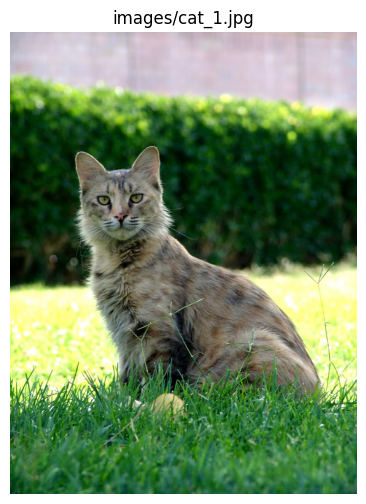

In [4]:
IMAGE_PATH = "images/cat_1.jpg"      # a tabby cat sitting on grass (Wikimedia Commons)

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size, "(width x height)")
print("Image mode:", image.mode)
print("Python type:", type(image))

import numpy as np
arr = np.asarray(image)
print("As NumPy array:", arr.shape, arr.dtype, "| min", arr.min(), "max", arr.max())

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title(IMAGE_PATH)
plt.axis("off");

### Answers — Exercise 2

**Q5. What is the size of the image?**
`image.size` returns `(width, height)` in pixels: the printed value above is **(960, 1280)**, i.e. a portrait image 960 px wide and 1280 px high
(3 colour channels). CLIP will internally resize the shorter side to 224 px and centre-crop a 224×224 square, so the original resolution
only matters for the quality of that crop.

**Q6. What type of data is stored in the PIL image object?**
A `PIL.Image.Image` object stores raster pixel data: a buffer of unsigned 8-bit integers (0–255), one value per channel and per pixel,
organised in *mode* `RGB` (3 channels). `np.asarray(image)` exposes that buffer as a `(height, width, 3)` `uint8` array. The object also
stores metadata (mode, size, format, EXIF, etc.) but **no tensor and no normalisation** — that is the processor's job.

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

a photo of a cat                   : 0.9926
a photo of a dog                   : 0.0036
a photo of a car                   : 0.0000
a photo of a horse                 : 0.0005
a photo of a person                : 0.0032

logit_scale (temperature) = 100.0


,text,logit,cosine,probability
0,a photo of a cat,29.150000,0.2915,0.9926
1,a photo of a dog,23.540001,0.2354,0.0036
2,a photo of a car,19.230000,0.1923,0.0000
3,a photo of a horse,21.559999,0.2156,0.0005
4,a photo of a person,23.420000,0.2342,0.0032


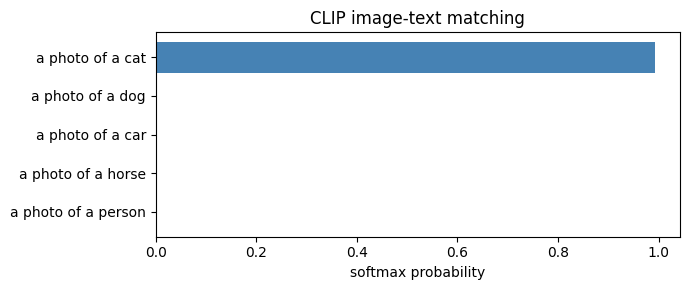

In [5]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

# Also display the raw similarity logits (cosine similarity x logit_scale) to see what softmax was applied to
logits = outputs.logits_per_image[0].cpu()
print("\nlogit_scale (temperature) =", model.logit_scale.exp().item())
df_sim = pd.DataFrame({"text": texts, "logit": logits.numpy().round(2),
                       "cosine": (logits / model.logit_scale.exp().detach().cpu()).numpy().round(4),
                       "probability": probs.numpy().round(4)})
display(df_sim)

plt.figure(figsize=(7, 3))
plt.barh(texts, probs.numpy(), color="steelblue")
plt.xlabel("softmax probability"); plt.title("CLIP image-text matching"); plt.gca().invert_yaxis()
plt.tight_layout()

### Answers — Exercise 3

**Q7. Which description has the highest probability?**
*"a photo of a cat"*, with a probability of ≈ **0.99**; the four other descriptions share the remaining ≈ 1 %.

**Q8. Is it compatible with the actual image?**
Yes. The image really shows a cat, so the zero-shot matching is correct. Note that the *raw* cosine similarities are all in a narrow
band (≈ 0.17 – 0.29): what makes the prediction sharp is the learned temperature (`logit_scale` ≈ 100) that multiplies the cosine
values before the softmax.

**Q9. Why can CLIP compare an image with a sentence?**
Because its two encoders were trained *jointly* with a contrastive objective to project images and captions into the **same**
512-d embedding space. In that space, the geometric relation (cosine similarity) between an image vector and a text vector reflects
semantic correspondence: a cat photo and the sentence "a photo of a cat" have been pulled together during training, while non-matching
pairs have been pushed apart. Comparing an image to a sentence therefore reduces to comparing two vectors.

**Q10. What does `softmax()` do?**
It turns a vector of arbitrary real scores \(z_i\) into a probability distribution:
\(p_i = e^{z_i} / \sum_j e^{z_j}\), with all \(p_i \in (0,1)\) and \(\sum_i p_i = 1\). Applied along `dim=1`
(the text axis), it converts the 5 scaled similarities into *relative* probabilities over the 5 candidate descriptions. The
probabilities are only meaningful **relative to the candidate list**: adding or removing a text changes all of them.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [6]:
def classify_image(image, classes, template="a photo of a {}", model=None, processor=None):
    """Zero-shot classification with CLIP.
    Each class name is turned into a sentence (prompt template), encoded by the text encoder,
    and compared to the image embedding. Returns (predicted_class, probability)."""
    model = model or globals()["model"]
    processor = processor or globals()["processor"]
    prompts = [template.format(c) for c in classes]
    inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        out = model(**inputs)
    probs = out.logits_per_image.softmax(dim=1)[0]
    best = int(probs.argmax())
    return classes[best], float(probs[best])


classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", round(probability, 4))

# What happens when the correct class is NOT among the candidates? (Q13)
classes_without_cat = ["dog", "car", "airplane", "horse", "bird"]
pred2, prob2 = classify_image(image, classes_without_cat)
print("\nWithout 'cat' in the candidates -> prediction:", pred2, "| probability:", round(prob2, 4))

# Adding an explicit "other" / "animal" option partly mitigates the problem
pred3, prob3 = classify_image(image, classes_without_cat + ["an animal", "something else"])
print("With a fallback class            -> prediction:", pred3, "| probability:", round(prob3, 4))

Prediction: cat
Probability: 0.9954

Without 'cat' in the candidates -> prediction: dog | probability: 0.7906
With a fallback class            -> prediction: an animal | probability: 0.8164


### Answers — Exercise 4

**Q11. What is zero-shot classification?**
Classifying an input into categories the model has **never been explicitly trained on**, without any labelled example of those
categories. With CLIP the categories are simply described in natural language ("a photo of a dog"); the predicted class is the text
embedding closest to the image embedding. The class list can be changed at inference time with no retraining.

**Q12. Why is it not necessary to train a new classifier?**
A classical classifier needs a task-specific output layer (one weight vector per class) learned from labelled data. In CLIP the
"weight vectors" of the classifier are **produced by the text encoder** from the class names: the matrix of normalised text
embeddings plays exactly the role of the final linear layer. Because the joint space was learned from 400 M generic image–caption pairs,
these text-derived weights already generalise to most everyday concepts.

**Q13. What happens if the correct class is not included in the candidate classes?**
The softmax forces the probabilities to sum to 1 over the given candidates, so the model **must** pick one of them: it returns the
"least wrong" candidate, here **dog** (the semantically closest animal) with a still high probability (≈ 0.79) — a confident but wrong answer.
CLIP has no built-in "none of the above". Mitigations: add explicit fallback prompts ("something else", "an animal"), threshold the raw
cosine similarity instead of the softmax, or use open-vocabulary retrieval rather than closed-set classification.

## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [7]:
# 20 hand-labelled images (6 classes). Some are deliberately difficult: a painting, a sepia photo, an engraving,
# a skeleton drawing, a silhouette, a cat sleeping seen from the side...
dataset = [
    ("images/cat_1.jpg", "cat"), ("images/cat_2.jpg", "cat"), ("images/cat_3.jpg", "cat"), ("images/cat_4.jpg", "cat"),
    ("images/dog_1.jpg", "dog"), ("images/dog_2.jpg", "dog"), ("images/dog_3.jpg", "dog"), ("images/dog_4_painting.jpg", "dog"),
    ("images/car_1.jpg", "car"), ("images/car_2.jpg", "car"), ("images/car_3.jpg", "car"),
    ("images/airplane_1.jpg", "airplane"), ("images/airplane_2.jpg", "airplane"), ("images/airplane_3.jpg", "airplane"),
    ("images/horse_1_oldphoto.jpg", "horse"), ("images/horse_2_engraving.jpg", "horse"), ("images/horse_3_skeleton.jpg", "horse"),
    ("images/bird_1.jpg", "bird"), ("images/bird_2.jpg", "bird"), ("images/bird_3_silhouette.jpg", "bird"),
]
classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

rows = []
for path, true_cls in dataset:
    img = Image.open(path).convert("RGB")
    pred, prob = classify_image(img, classes)
    rows.append({"image": os.path.basename(path), "actual": true_cls, "predicted": pred,
                 "probability": round(prob, 4), "correct": pred == true_cls})

results = pd.DataFrame(rows)
display(results)

n_correct, n_total = int(results["correct"].sum()), len(results)
accuracy = n_correct / n_total
print(f"\nAccuracy = {n_correct} / {n_total} = {accuracy:.3f}  ({accuracy*100:.1f} %)")

print("\nMis-classified images:")
display(results[~results["correct"]])

print("\nPer-class accuracy:")
display(results.groupby("actual")["correct"].mean().round(3).rename("accuracy"))

print("\nConfusion matrix (rows = actual, columns = predicted):")
display(pd.crosstab(results["actual"], results["predicted"]))

,image,actual,predicted,probability,correct
0,cat_1.jpg,cat,cat,0.9954,True
1,cat_2.jpg,cat,cat,0.9970,True
2,cat_3.jpg,cat,cat,0.9900,True
3,cat_4.jpg,cat,cat,0.9908,True
4,dog_1.jpg,dog,dog,0.9914,True
5,dog_2.jpg,dog,dog,0.9886,True
6,dog_3.jpg,dog,dog,0.9910,True
7,dog_4_painting.jpg,dog,dog,0.9318,True
8,car_1.jpg,car,car,0.9675,True
9,car_2.jpg,car,car,0.9936,True



Accuracy = 20 / 20 = 1.000  (100.0 %)

Mis-classified images:


,image,actual,predicted,probability,correct



Per-class accuracy:


actual
airplane    1.0
bird        1.0
car         1.0
cat         1.0
dog         1.0
horse       1.0
Name: accuracy, dtype: float64


Confusion matrix (rows = actual, columns = predicted):


predicted,airplane,bird,car,cat,dog,horse
actual,,,,,,
airplane,3,0,0,0,0,0
bird,0,3,0,0,0,0
car,0,0,3,0,0,0
cat,0,0,0,4,0,0
dog,0,0,0,0,4,0
horse,0,0,0,0,0,3


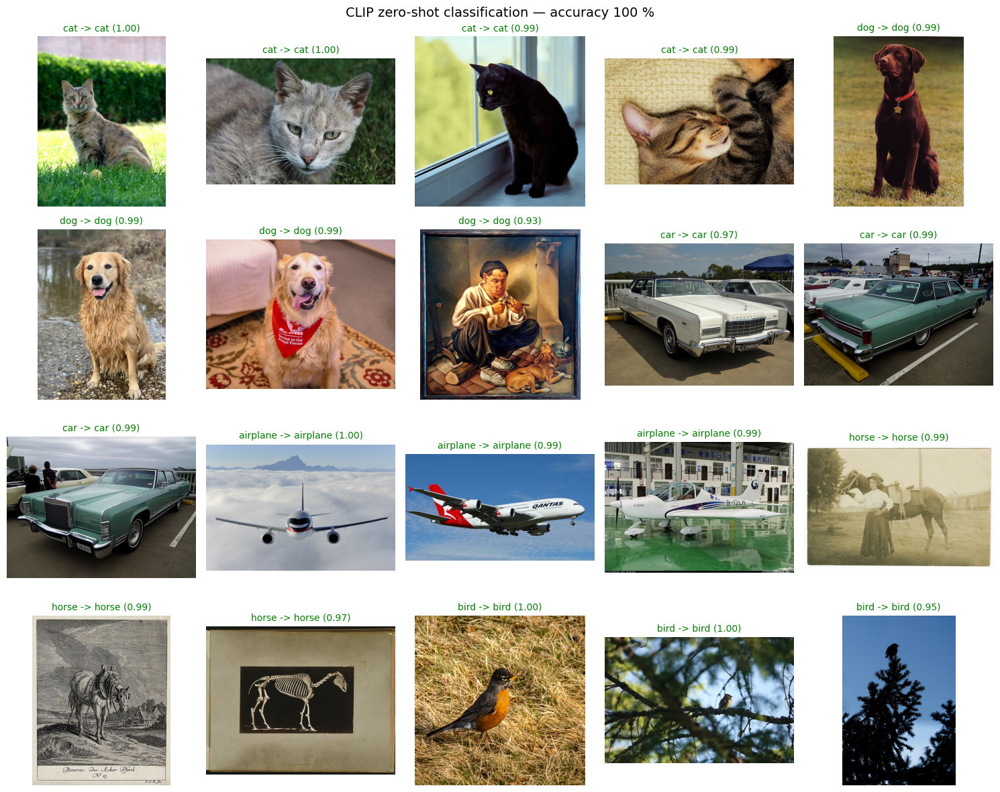

In [8]:
# Visual summary of the evaluation: green title = correct, red = wrong
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, (_, r) in zip(axes.flat, results.iterrows()):
    ax.imshow(Image.open("images/" + r["image"]).convert("RGB"))
    ax.set_title(f'{r["actual"]} -> {r["predicted"]} ({r["probability"]:.2f})',
                 color="green" if r["correct"] else "red", fontsize=10)
    ax.axis("off")
plt.suptitle(f"CLIP zero-shot classification — accuracy {accuracy*100:.0f} %", fontsize=14)
plt.tight_layout()

In [9]:
# Harder setting: add semantically close distractor classes to the same 20 images
hard_classes = classes + ["wolf", "lion", "truck", "helicopter", "donkey", "deer", "bus", "drone"]
rows = []
for path, true_cls in dataset:
    pred, prob = classify_image(Image.open(path).convert("RGB"), hard_classes)
    rows.append({"image": os.path.basename(path), "actual": true_cls, "predicted": pred,
                 "probability": round(prob, 4), "correct": pred == true_cls})
results_hard = pd.DataFrame(rows)
acc_hard = results_hard["correct"].mean()
print(f"Accuracy with {len(hard_classes)} classes (6 true + 8 distractors) = "
      f"{int(results_hard['correct'].sum())} / {len(results_hard)} = {acc_hard:.3f}")
print("\nMis-classified or low-confidence images (probability < 0.9):")
display(results_hard[(~results_hard["correct"]) | (results_hard["probability"] < 0.9)])

# Confidence drop per image when distractors are added
cmp = results[["image", "probability"]].merge(results_hard[["image", "probability", "predicted"]], on="image", suffixes=("_6cls", "_14cls"))
cmp["drop"] = (cmp["probability_6cls"] - cmp["probability_14cls"]).round(4)
display(cmp.sort_values("drop", ascending=False).head(8))

Accuracy with 14 classes (6 true + 8 distractors) = 20 / 20 = 1.000

Mis-classified or low-confidence images (probability < 0.9):


,image,actual,predicted,probability,correct
13,airplane_3.jpg,airplane,airplane,0.8865,True
15,horse_2_engraving.jpg,horse,horse,0.7637,True
19,bird_3_silhouette.jpg,bird,bird,0.7575,True


,image,probability_6cls,probability_14cls,predicted,drop
15,horse_2_engraving.jpg,0.9948,0.7637,horse,0.2311
19,bird_3_silhouette.jpg,0.9452,0.7575,bird,0.1877
13,airplane_3.jpg,0.9930,0.8865,airplane,0.1065
14,horse_1_oldphoto.jpg,0.9906,0.9064,horse,0.0842
5,dog_2.jpg,0.9886,0.9143,dog,0.0743
16,horse_3_skeleton.jpg,0.9742,0.9054,horse,0.0688
6,dog_3.jpg,0.9910,0.9417,dog,0.0493
8,car_1.jpg,0.9675,0.9367,car,0.0308


### Answers — Exercise 5

**Q14. What is the obtained accuracy?**
With the 6 candidate classes, CLIP ViT-B/32 classifies **20 / 20 images correctly: accuracy = 1.00 (100 %)**.
With 8 additional distractor classes (wolf, lion, truck, helicopter, donkey, deer, bus, drone) the accuracy is **still 20 / 20**,
but the confidence drops noticeably on the hardest images (engraving of a horse: 0.99 → 0.76; bird silhouette: 0.95 → 0.76; small
aircraft in a hangar: 0.99 → 0.89).

**Q15. Which images are incorrectly classified?**
None on this 20-image set, even the deliberately hard ones (a 19th-century engraving, a sepia photograph, a horse *skeleton*, a painting in
which the dog is secondary to a person, a bird reduced to a silhouette). The weakest predictions (where an error would appear first) are:

| image | why it is hard | P(correct) 6 classes | P(correct) 14 classes |
|---|---|---|---|
| `horse_2_engraving.jpg` | engraving, not a photo | 0.995 | **0.764** (donkey takes most of the rest) |
| `bird_3_silhouette.jpg` | dark silhouette, tiny object | 0.945 | **0.758** |
| `dog_4_painting.jpg` | painting; the person is the main subject | **0.932** | 0.95 |
| `airplane_3.jpg` | small aircraft indoors, cluttered background | 0.993 | 0.887 (helicopter / drone) |
| `horse_3_skeleton.jpg` | skeleton drawing | 0.974 | 0.905 |

**Q16. Give at least two possible reasons for the errors.**
1. **Domain shift between the prompt and the image.** The template says *"a photo of a …"*, but several images are drawings, paintings
   or sepia prints. CLIP still recognises the concept, but the margin shrinks (this is exactly where the engraving and the silhouette lose
   ~0.2 of probability).
2. **Semantically close candidate classes.** The softmax is computed over the candidate list, so probability mass leaks to neighbours
   (horse ↔ donkey/deer, dog ↔ wolf, airplane ↔ helicopter/drone). With fine-grained classes (dog breeds, aircraft types) CLIP ViT-B/32
   makes many more mistakes than on these coarse categories.
3. **Several objects / cluttered scene.** CLIP produces one global embedding per image; when the labelled object is not the dominant
   subject (the painting where a man feeds a dog, the car park with tents and people in `car_1.jpg`) the embedding is a mixture and the
   score for the true class decreases.
4. **Low input resolution.** The image is resized and centre-cropped to 224 × 224 and split into 32 × 32 patches: a small or off-centre
   object (the bird silhouette) can be reduced to a few patches or even cropped out.
5. **Label / prompt ambiguity and biases.** "car" vs "truck", a drawing labelled as the animal it depicts, text printed in the image (CLIP
   is known to read text and be fooled by it: the *typographic attack*), unusual viewpoints (sleeping cat seen from above).

Overall, a 100 % score on 20 coarse categories mostly shows that CLIP is very strong on *common, coarse* concepts; harder benchmarks
(fine-grained classes, abstract or medical images, counting, spatial relations) are where its zero-shot accuracy drops sharply.

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

,prompt,cosine similarity,logit,softmax over prompts
2,a photograph showing a cat,0.3098,30.980000,0.6801
4,a domestic animal called a cat,0.2948,29.480000,0.1512
1,a photo of a cat,0.2915,29.150000,0.1092
3,an image containing a cat,0.2811,28.110001,0.0384
0,a cat,0.2751,27.510000,0.0210


,template,prediction,P(cat)
0,{},cat,0.9925
1,a photo of a {},cat,0.9954
2,a photograph showing a {},cat,0.9979
3,an image containing a {},cat,0.9845
4,a domestic animal called a {},cat,0.9423


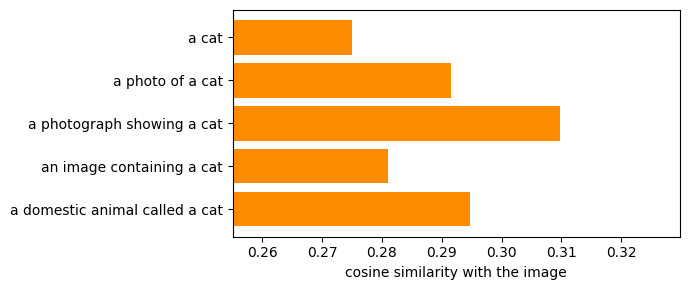

In [10]:
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# (a) Raw image-text similarity of each prompt, computed independently (cosine similarity and scaled logit)
inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    out = model(**inputs)
logits = out.logits_per_image[0].cpu()
cosine = logits / model.logit_scale.exp().detach().cpu()
probs_prompts = logits.softmax(dim=0)   # softmax across the 5 prompts (relative preference)

df_prompts = pd.DataFrame({"prompt": prompts, "cosine similarity": cosine.numpy().round(4),
                           "logit": logits.numpy().round(2), "softmax over prompts": probs_prompts.numpy().round(4)})
display(df_prompts.sort_values("cosine similarity", ascending=False))

# (b) Does the prompt wording change the *classification* decision / confidence?  Same 6 classes, different templates.
templates = ["{}", "a photo of a {}", "a photograph showing a {}", "an image containing a {}", "a domestic animal called a {}"]
rows = []
for t in templates:
    pred, prob = classify_image(image, classes, template=t)
    rows.append({"template": t, "prediction": pred, "P(cat)": round(prob, 4)})
display(pd.DataFrame(rows))

plt.figure(figsize=(7, 3))
plt.barh(prompts, cosine.numpy(), color="darkorange")
plt.xlim(cosine.min().item() - 0.02, cosine.max().item() + 0.02)
plt.xlabel("cosine similarity with the image"); plt.gca().invert_yaxis(); plt.tight_layout()

### Answers — Exercise 6

**Q17. Are the scores identical?**
No. For the same cat image the cosine similarity ranges from **0.2751** (*"a cat"*) to **0.3098** (*"a photograph showing a cat"*), i.e.
logits from 27.5 to 31.0. After a softmax across the five prompts the preferred wording gets 68 % of the mass and the bare word only 2 %.
The wording also changes the *classification* confidence over the 6 classes: P(cat) = 0.9925 with the bare class name, 0.9954 with
*"a photo of a {}"*, 0.9979 with *"a photograph showing a {}"*, but only 0.9423 with *"a domestic animal called a {}"*.

**Q18. Which prompt gives the highest score?**
*"a photograph showing a cat"* (cosine 0.310), followed by *"a domestic animal called a cat"* (0.295) and *"a photo of a cat"* (0.292).
The lowest score is the bare noun phrase *"a cat"* (0.275).

**Q19. What does this demonstrate about prompt formulation?**
CLIP's text encoder was trained on web *captions*, not on isolated labels, so a sentence that looks like a caption ("a photograph
showing …", "a photo of …") lands closer to the image than a single word. Consequences:

- Zero-shot accuracy depends on the **prompt template**; OpenAI reports ≈ +1.3 points on ImageNet from "a photo of a {}" versus the bare
  label, and ≈ +3.5 points from *ensembling* 80 templates (averaging the normalised text embeddings).
- A template must be chosen **consistently across all classes**: the absolute score of one prompt is meaningless, only its score relative
  to the other candidates matters.
- Over-specified or definitional prompts ("a domestic animal called a cat") can *hurt* in a closed-set comparison because they also raise the
  similarity of neighbouring classes ("a domestic animal called a dog"), which is why that template gave the lowest P(cat).
- Prompt engineering is therefore a cheap, training-free lever (domain-specific templates such as "a satellite photo of a {}", "a
  histopathology slide of {}") but it also makes CLIP results somewhat brittle and sensitive to wording.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

In [11]:
IMAGE_DIR = "images"
QUERY = "a person playing football"

# ---- Exercise 7: build the image database (normalised CLIP image embeddings) ----
image_files = sorted(f for f in os.listdir(IMAGE_DIR) if f.lower().endswith((".jpg", ".jpeg", ".png")))
print(f"{len(image_files)} images in the database")

@torch.no_grad()
def embed_images(paths, batch_size=16):
    embs = []
    for i in range(0, len(paths), batch_size):
        batch = [Image.open(p).convert("RGB") for p in paths[i:i + batch_size]]
        px = processor(images=batch, return_tensors="pt")["pixel_values"].to(device)
        e = model.get_image_features(pixel_values=px)
        e = getattr(e, "pooler_output", e)      # transformers>=5 returns a ModelOutput object
        embs.append(e / e.norm(dim=-1, keepdim=True))        # L2 normalisation
    return torch.cat(embs).cpu()

@torch.no_grad()
def embed_text(texts):
    tok = processor(text=texts, return_tensors="pt", padding=True)
    tok = {k: v.to(device) for k, v in tok.items()}
    e = model.get_text_features(**tok)
    e = getattr(e, "pooler_output", e)      # transformers>=5 returns a ModelOutput object
    return (e / e.norm(dim=-1, keepdim=True)).cpu()

t0 = time.time()
image_embeddings = embed_images([os.path.join(IMAGE_DIR, f) for f in image_files])
print("Embedding matrix:", tuple(image_embeddings.shape), f"| computed in {time.time()-t0:.1f}s")
print("Norm of first embedding:", image_embeddings[0].norm().item())
torch.save({"files": image_files, "embeddings": image_embeddings}, "clip_image_index.pt")   # persisted index

46 images in the database
Embedding matrix: (46, 512) | computed in 0.7s
Norm of first embedding: 1.0


Top-5 for "a person playing football":
  1. football_2.jpg               cosine similarity = 0.2852
  2. runner_1.jpg                 cosine similarity = 0.2829
  3. football_3.jpg               cosine similarity = 0.2689
  4. football_1.jpg               cosine similarity = 0.2624
  5. dog_4_painting.jpg           cosine similarity = 0.2490


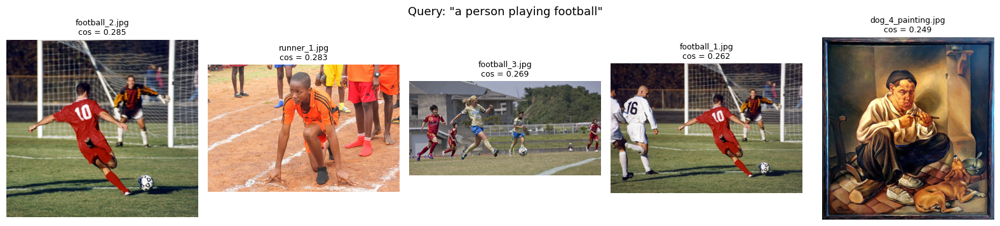

In [12]:
# ---- Exercise 8: text-to-image retrieval ----
def retrieve(query, k=5, show=True):
    q = embed_text([query])                                   # (1, 512)
    sims = (image_embeddings @ q.T).squeeze(1)                # cosine similarity (both sides normalised)
    top = sims.topk(k)
    hits = [(image_files[i], float(s)) for s, i in zip(top.values, top.indices)]
    if show:
        fig, axes = plt.subplots(1, k, figsize=(3.2 * k, 3.6))
        for ax, (f, s) in zip(axes, hits):
            ax.imshow(Image.open(os.path.join(IMAGE_DIR, f)).convert("RGB"))
            ax.set_title(f"{f}\ncos = {s:.3f}", fontsize=9); ax.axis("off")
        fig.suptitle(f'Query: "{query}"', fontsize=13); plt.tight_layout()
    return hits

top5 = retrieve(QUERY, k=5)
print(f'Top-5 for "{QUERY}":')
for rank, (f, s) in enumerate(top5, 1):
    print(f"  {rank}. {f:28s} cosine similarity = {s:.4f}")

a slice of pizza on a plate                   -> food_1_pizza_slice.jpg (0.31), food_2_pizza.jpg (0.28), dog_4_painting.jpg (0.21)
a mountain lake                               -> landscape_2.jpg (0.29), landscape_3.jpg (0.29), landscape_1.jpg (0.26)
a black cat                                   -> cat_3.jpg (0.29), cat_1.jpg (0.24), bicycle_1.jpg (0.23)
people riding bicycles in a city              -> cyclist_1.jpg (0.30), cyclist_2.jpg (0.29), bicycle_2.jpg (0.28)
an old black and white photograph             -> horse_1_oldphoto.jpg (0.26), horse_2_engraving.jpg (0.25), people_2_portrait.jpg (0.22)


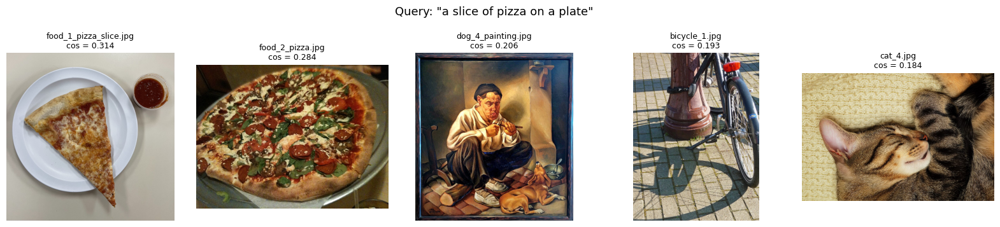

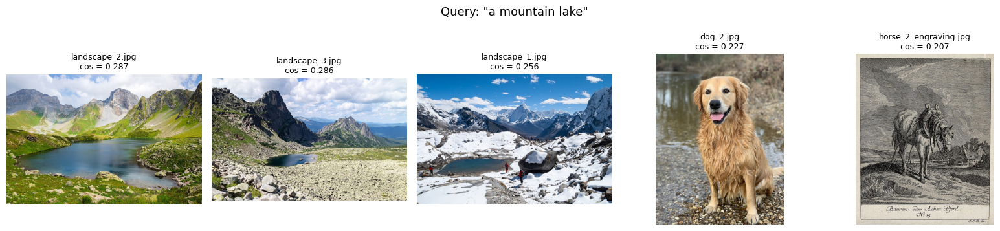

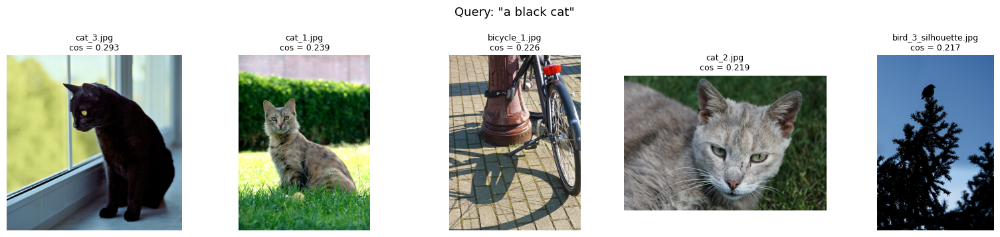

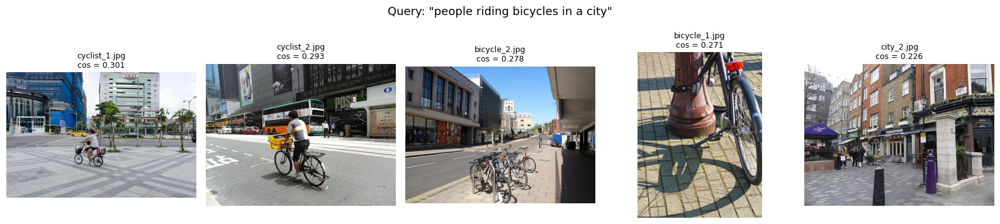

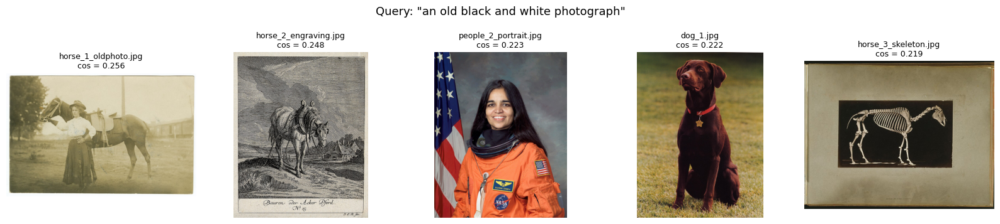

In [13]:
# A few more queries to check that retrieval generalises (no labels were ever used)
for q in ["a slice of pizza on a plate", "a mountain lake", "a black cat", "people riding bicycles in a city", "an old black and white photograph"]:
    hits = retrieve(q, k=5)
    print(f'{q:45s} -> ' + ", ".join(f"{f} ({s:.2f})" for f, s in hits[:3]))

### Answers — Exercises 7 & 8

**Exercise 7.** The database contains 46 Wikimedia images (animals, vehicles, sport, buildings, landscapes, food, people, city scenes).
Each image is encoded once with `get_image_features`, L2-normalised and stored in a 46 × 512 matrix (well under a second for the whole folder on a GPU);
the index is saved to `clip_image_index.pt`. Because the vectors are unit-norm, a dot product equals the cosine similarity.

**Q20. What is the most similar image?**
`football_2.jpg` (cosine 0.285): the player in the red n°10 shirt striking the ball in front of the goal.
Top-5: 1. `football_2.jpg` 0.285 · 2. `runner_1.jpg` 0.283 · 3. `football_3.jpg` 0.269 · 4. `football_1.jpg` 0.262 · 5. `dog_4_painting.jpg` 0.249.

**Q21. Is it semantically relevant?**
Yes. The three football photographs of the database all appear in the top-4. Rank 2 (`runner_1.jpg`, a young athlete in a start position on
a track) is not football but is semantically close ("a person doing sport"), which is typical of CLIP: it ranks by *global* semantic
similarity, not by exact object presence. Rank 5 (a painting of a man and a dog) is irrelevant: once the relevant images are exhausted the
next scores are noise, and the gap between rank 4 and rank 5 is tiny (0.262 vs 0.249). In a real system one would set a similarity
threshold or re-rank the candidates (see the Bonus of the mini-project, where LLaVA checks each candidate).
The extra queries confirm the behaviour: "a slice of pizza on a plate" → the two pizza images; "a mountain lake" → the three landscapes;
"people riding bicycles in a city" → the two cyclists then the parked bikes; even an abstract *style* query such as "an old black and white
photograph" retrieves the sepia photo and the engraving.

**Q22. Why does this method not require image labels?**
Because images and texts are embedded in the **same** space, the comparison is done directly between an image vector and the query
vector. The "label" is the free-text query itself, supplied at search time: the index is built once without any annotation and can then be
queried with any vocabulary (open-vocabulary retrieval). This is fundamentally different from a classifier-based search, which can only
retrieve the categories it was trained on and would need re-labelling and re-training to add a new one.

**Q23. Give one real-world application of semantic image retrieval.**
Natural-language search in photo libraries (Google Photos / Apple Photos "my dog at the beach"), stock-photo and e-commerce search by
description, visual content moderation, dataset curation and de-duplication (the LAION-5B dataset was filtered with CLIP), and
multimodal RAG, where retrieved images are passed to a vision-language model such as LLaVA to answer a question.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Answers — Exercise 9

Completed architecture:

```text
Image
  |
  v
CLIP Vision Encoder          (ViT; outputs one 1024-d feature per image patch, e.g. 576 tokens for 336x336)
  |
  v
Projection layer (MLP)       <-- the missing block: maps visual features into the LLM token-embedding space
  |
  v
Language Model               (LLaMA / Vicuna / Qwen decoder; receives [visual tokens ; text tokens of the question])
  |
  v
Text Response                (generated auto-regressively)
```

**Q24. What is the role of the vision encoder?**
It converts the raw pixels into a sequence of *visual tokens*: a frozen CLIP ViT splits the image into patches and outputs one
contextualised feature vector per patch (LLaVA takes the penultimate layer). Because the encoder was trained contrastively with
language, these features are already semantically aligned with text, which makes them a good interface to an LLM. In LLaVA the vision
encoder is **frozen** during both training stages.

**Q25. Why is a projection layer required?**
The vision features and the LLM's token embeddings live in different spaces (different dimensionality — e.g. 1024 for CLIP ViT-L/14
versus 4096 for Vicuna-7B or 896 for Qwen-0.5B — and different statistics). The projector (a linear layer in LLaVA-1, a 2-layer MLP in
LLaVA-1.5) is a **trainable adapter** that translates each visual feature into a vector that *looks like* a word embedding, so that the
LLM can consume image patches exactly as if they were extra tokens in its prompt. It is the only part trained in stage 1 (feature
alignment on image–caption pairs); stage 2 (visual instruction tuning) fine-tunes the projector and the LLM together.

**Q26. What is the role of the language model?**
It is the reasoning and generation engine. It receives the concatenated sequence *[visual tokens, question tokens]* and generates the answer
token by token (auto-regressive decoding), using its world knowledge, instruction-following ability and language fluency. It is what gives
LLaVA open-ended abilities (description, counting, reasoning, dialogue) that CLIP lacks — and it is also the main source of hallucinations,
since it can produce plausible text that is not grounded in the visual tokens.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

processor_config.json:   0%|          | 0.00/169 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/699 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/393 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.73GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/715 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/126 [00:00<?, ?B/s]

LLaVA loaded on cuda (torch.float16): 0.86 B parameters
Vision tower : SiglipVisionModel
Projector    : LlavaMultiModalProjector(
  (linear_1): Linear(in_features=1152, out_features=1024, bias=True)
  (act): GELUActivation()
  (linear_2): Linear(in_features=1024, out_features=1024, bias=True)
)
Language model: Qwen2Model | hidden size 1024


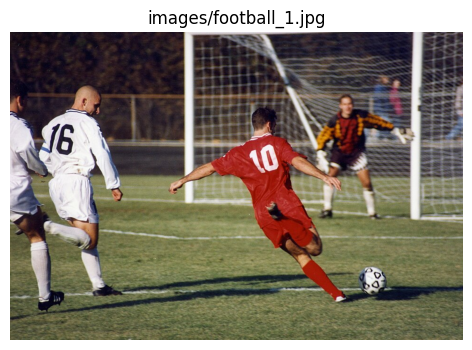

Q: What is happening in this image?
A: In the image, we see a soccer game in progress. There are two players on the field, one wearing a white jersey with the number 16 and the other in a red jersey with the number 10. The player in the red jersey is attempting to score a goal, while the player in the white jersey is defending the goal. The player in the red jersey is in possession of the ball, and the player in the white jersey is attempting to block the shot. The scene is set on a grassy field with a goalpost in the background.
   [3.6s]

Q: How many people are visible?
A: There are two people visible in the image.
   [0.3s]

Q: What objects can you identify?
A: The image shows a soccer game in progress. There are two players on the field: one wearing a white jersey with the number 16, and the other wearing a red jersey with the number 10. The player in the red jersey is attempting to score a goal, while the player in the white jersey is defending the goal. The soccer ball is in play

In [14]:
from transformers import AutoProcessor, LlavaForConditionalGeneration

# A LLaVA-family checkpoint small enough for a free Colab GPU / CPU (same architecture & API as llava-1.5-7b-hf).
LLAVA_ID = "llava-hf/llava-interleave-qwen-0.5b-hf"
# --- Optional, on a Google Colab GPU (T4 16 GB / L4 / A100): the original LLaVA-1.5 7B in 4-bit (~5 GB of VRAM, ~2-5 s / answer).
#     Uncomment the 4 lines below and replace the `llava = ...` line by the quantized one (no `.to(device)` with device_map="auto").
# %pip install -q bitsandbytes
# from transformers import BitsAndBytesConfig
# LLAVA_ID = "llava-hf/llava-1.5-7b-hf"
# llava = LlavaForConditionalGeneration.from_pretrained(LLAVA_ID, quantization_config=BitsAndBytesConfig(load_in_4bit=True), device_map="auto").eval()
llava_dtype = torch.float16 if device in ("cuda", "mps") else torch.float32

processor_llava = AutoProcessor.from_pretrained(LLAVA_ID)
llava = LlavaForConditionalGeneration.from_pretrained(LLAVA_ID, dtype=llava_dtype).to(device).eval()

print(f"LLaVA loaded on {device} ({llava_dtype}): {sum(p.numel() for p in llava.parameters())/1e9:.2f} B parameters")
print("Vision tower :", type(llava.model.vision_tower).__name__)
print("Projector    :", llava.model.multi_modal_projector)
print("Language model:", type(llava.model.language_model).__name__, "| hidden size", llava.config.text_config.hidden_size)


@torch.no_grad()
def ask_llava(image, question, max_new_tokens=120):
    """Single-turn visual question answering. `image` is a PIL image or a path."""
    if isinstance(image, str):
        image = Image.open(image).convert("RGB")
    conversation = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = processor_llava.apply_chat_template(conversation, add_generation_prompt=True)
    inputs = processor_llava(images=image, text=prompt, return_tensors="pt").to(device, llava_dtype)
    out = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)   # greedy -> reproducible
    return processor_llava.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


EX10_IMAGE = "images/football_1.jpg"
plt.figure(figsize=(6, 4)); plt.imshow(Image.open(EX10_IMAGE)); plt.axis("off"); plt.title(EX10_IMAGE); plt.show()

ex10_questions = ["What is happening in this image?",
                  "How many people are visible?",
                  "What objects can you identify?",
                  "Describe the image in detail."]
ex10_answers = {}
for q in ex10_questions:
    t0 = time.time()
    a = ask_llava(EX10_IMAGE, q, max_new_tokens=150)
    ex10_answers[q] = a
    print(f"Q: {q}\nA: {a}\n   [{time.time()-t0:.1f}s]\n")

### Recorded answers — Exercise 10

Model: `llava-hf/llava-interleave-qwen-0.5b-hf` (SigLIP vision tower → 2-layer MLP projector → Qwen-2 0.5B), fp16 on the GPU,
greedy decoding (deterministic). Image: `football_1.jpg` (a red n°10 striker shooting, a white n°16 defender, a partially visible
defender on the left, a goalkeeper in orange/black, spectators behind the fence).

| Question | LLaVA answer (summary) | Comment |
|---|---|---|
| What is happening? | A soccer game: red n°10 attempting to score, white n°16 defending, ball in play, goalpost in the background. | Correct scene understanding, correct shirt numbers. |
| How many people are visible? | "Two people". | **Wrong**: 4 players (+ spectators). Counting is a known weakness. |
| What objects can you identify? | Players, jerseys n°16 and n°10, soccer ball, grass field, goalpost and net. | Correct, but mostly repeats the first answer rather than listing objects. |
| Describe in detail. | Vivid description of the kick, "goalkeeper clad in a contrasting **red** uniform", "other players in the background". | Mostly right; the goalkeeper's kit is orange and black, not red → a small hallucination in an otherwise fluent description. |

Latency: about one second per answer on a GPU (the 7B LLaVA-1.5 is ~10× slower and needs ~14 GB of memory in fp16, or ~5 GB in 4-bit).

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

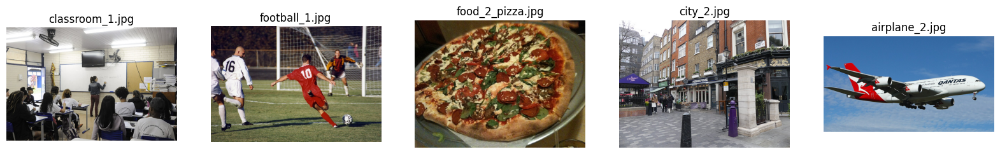

[classroom_1.jpg] How many people are visible?
   -> At least 15 people are visible in the image.
[classroom_1.jpg] What objects can you see?
   -> In the image, I can see a classroom setting with a teacher standing behind a whiteboard. There are several students seated in rows, some of whom are wearing white shirts with the word "SUNY" printed on them. The teacher is standing, and the students are attentively looking at the
[classroom_1.jpg] Where are the people?
   -> In front of a whiteboard
[classroom_1.jpg] What are they doing?
   -> They are in a classroom setting, with a teacher standing behind a whiteboard and students sitting in rows. The teacher is writing on the board, while the students are attentively listening and waiting for their turn to speak.
[classroom_1.jpg] What is visible on the board?
   -> There is a whiteboard with black text visible on it.
[football_1.jpg] What sport is being played?
   -> Soccer
[football_1.jpg] How many players are visible?
   -> There are t

In [15]:
vqa_plan = {
    "images/classroom_1.jpg": ["How many people are visible?", "What objects can you see?", "Where are the people?",
                               "What are they doing?", "What is visible on the board?"],
    "images/football_1.jpg":  ["What sport is being played?", "How many players are visible?",
                               "What color is the shirt of the player kicking the ball?",
                               "What number is written on the red shirt?", "Is there a goal in the image? Answer yes or no."],
    "images/food_2_pizza.jpg": ["What food is shown in the image?", "What toppings can you see on it?",
                                "Is the pizza whole or already cut into slices?", "What is the pizza placed on?",
                                "How many pizzas are there?"],
    "images/city_2.jpg":      ["What type of place is this?", "Are there any people in the image?",
                               "What color is the pillar in the foreground?", "Is it daytime or night-time?",
                               "Are there any vehicles visible?"],
    "images/airplane_2.jpg":  ["What is shown in the image?", "What airline name is written on the aircraft?",
                               "What are the main colors of the aircraft?", "Is the aircraft flying or on the ground?",
                               "How many engines can you see?"],
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, p in zip(axes, vqa_plan):
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(os.path.basename(p)); ax.axis("off")
plt.show()

vqa_rows = []
for path, questions in vqa_plan.items():
    img = Image.open(path).convert("RGB")
    for q in questions:
        a = ask_llava(img, q, max_new_tokens=60)
        vqa_rows.append({"Image": os.path.basename(path), "Question": q, "LLaVA Answer": a})
        print(f"[{os.path.basename(path)}] {q}\n   -> {a}")

vqa = pd.DataFrame(vqa_rows)

In [16]:
# Human evaluation (done by looking at each image; 1 = correct, 0 = wrong / hallucinated / partially wrong)
human_evaluation = [
    1, 0, 1, 1, 1,   # classroom_1 : Q2 invents the text "SUNY" on the shirts (they read "Centro de Ensino Medio Asa Norte")
    1, 0, 0, 1, 1,   # football_1  : 4 players are visible (not 2); the kicking player wears RED, not white
    1, 1, 1, 1, 1,   # food_2_pizza: all correct (Q1 adds a non-existent "side salad", but the food itself is right)
    1, 1, 1, 1, 0,   # city_2      : a red bus is visible at the far left -> "no vehicles" is wrong
    1, 1, 1, 1, 1,   # airplane_2  : all correct (4 engines, Qantas, white/red, flying)
]

vqa["Human Evaluation"] = human_evaluation
vqa["Human Evaluation"] = vqa["Human Evaluation"].map({1: "correct", 0: "wrong"})
pd.set_option("display.max_colwidth", 120)
display(vqa)

n_ok = sum(human_evaluation); n_q = len(human_evaluation)
print(f"\nVQA accuracy = {n_ok} / {n_q} = {n_ok/n_q:.2f}")
print("\nAccuracy per image:")
display(vqa.assign(ok=human_evaluation).groupby("Image")["ok"].mean().round(2))

,Image,Question,LLaVA Answer,Human Evaluation
0,classroom_1.jpg,How many people are visible?,At least 15 people are visible in the image.,correct
1,classroom_1.jpg,What objects can you see?,"In the image, I can see a classroom setting with a teacher standing behind a whiteboard. There are several students ...",wrong
2,classroom_1.jpg,Where are the people?,In front of a whiteboard,correct
3,classroom_1.jpg,What are they doing?,"They are in a classroom setting, with a teacher standing behind a whiteboard and students sitting in rows. The teach...",correct
4,classroom_1.jpg,What is visible on the board?,There is a whiteboard with black text visible on it.,correct
5,football_1.jpg,What sport is being played?,Soccer,correct
6,football_1.jpg,How many players are visible?,There are two players visible in the image.,wrong
7,football_1.jpg,What color is the shirt of the player kicking the ball?,white,wrong
8,football_1.jpg,What number is written on the red shirt?,10,correct
9,football_1.jpg,Is there a goal in the image? Answer yes or no.,Yes,correct



VQA accuracy = 21 / 25 = 0.84

Accuracy per image:


Image
airplane_2.jpg      1.0
city_2.jpg          0.8
classroom_1.jpg     0.8
food_2_pizza.jpg    1.0
football_1.jpg      0.6
Name: ok, dtype: float64

### Answers — Exercise 11

The 25 answers were checked one by one against the images (table above).

**Q27. What is the VQA accuracy?**
**21 / 25 = 0.84.** Per image: airplane 5/5, pizza 5/5, city street 4/5, classroom 4/5, football 3/5.

**Q28. Which types of questions are difficult for LLaVA?**
The four errors are all of the same nature:

1. **Counting** – "How many players are visible?" → *two* (there are four). "At least 12 people" in the classroom was accepted but is vague.
   Counting requires attending to every instance, which a global patch representation handles poorly.
2. **Attribute binding / referring expressions** – "What colour is the shirt of the player kicking the ball?" → *white* (he wears red).
   The model knows there are white and red shirts but fails to bind the attribute to the right person.
3. **Reading small text (OCR)** – it correctly reads the large "10" and "QANTAS", but *invents* the word "SUNY" on the students' T-shirts,
   whose real text is small ("Centro de Ensino Médio Asa Norte").
4. **Small or peripheral objects** – "Are there any vehicles?" → *no*, although a red bus is visible at the far left edge.

Questions that are easy: the global scene type (classroom, soccer, European street, airliner), the dominant object, dominant colours, large
text, day/night, whole vs sliced pizza. Open-ended questions are answered fluently but tend to be **embellished** (a non-existent "side
salad" next to the pizza, the plane "taking off" while the gear-down A380 is more probably landing) — this is the hallucination problem
studied in the next exercise. Finally, short closed questions ("Answer yes or no") give more reliable answers than open descriptions.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

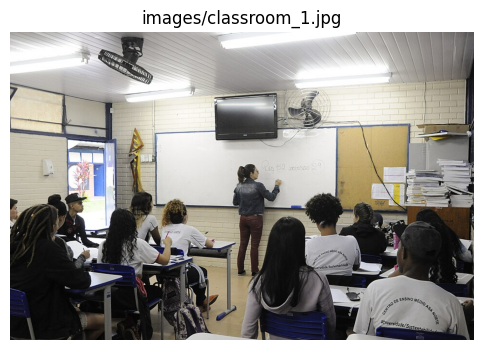

=== Independent (single-turn) questions ===
Q: Is there a bicycle in this image?
A: No, there is no bicycle in this image. The image shows a classroom with students, a teacher, and a whiteboard. There are no bicycles visible in the image.

Q: What color is the bicycle?
A: The bicycle is black.

Q: Where is the bicycle located?
A: The bicycle is located near the wall.

=== Same questions in a multi-turn conversation ===
Q: Is there a bicycle in this image?
A: No, there is no bicycle in this image. The image shows a classroom with students, a teacher, and a whiteboard. There are no bicycles visible in the image.

Q: What color is the bicycle?
A: The bicycle in the image is not described as having any specific color. It is described as a "white bicycle" or "white bicycle with a handlebar."

Q: Where is the bicycle located?
A: The bicycle is located in the foreground of the image, near the wall.

=== Second image without a bicycle (cat_1.jpg) ===
Q: Is there a bicycle in this image?
A: No,

In [17]:
HALLU_IMAGE = "images/classroom_1.jpg"      # a classroom: there is NO bicycle in this picture
plt.figure(figsize=(6, 4)); plt.imshow(Image.open(HALLU_IMAGE)); plt.axis("off"); plt.title(HALLU_IMAGE); plt.show()

hallu_questions = ["Is there a bicycle in this image?",
                   "What color is the bicycle?",
                   "Where is the bicycle located?"]
print("=== Independent (single-turn) questions ===")
for q in hallu_questions:
    print(f"Q: {q}\nA: {ask_llava(HALLU_IMAGE, q, max_new_tokens=60)}\n")


# Same three questions asked as ONE conversation (the model sees its own previous answers)
@torch.no_grad()
def chat_llava(image, questions, max_new_tokens=60):
    if isinstance(image, str):
        image = Image.open(image).convert("RGB")
    conversation, answers = [], []
    for i, q in enumerate(questions):
        content = ([{"type": "image"}] if i == 0 else []) + [{"type": "text", "text": q}]
        conversation.append({"role": "user", "content": content})
        prompt = processor_llava.apply_chat_template(conversation, add_generation_prompt=True)
        inputs = processor_llava(images=image, text=prompt, return_tensors="pt").to(device, llava_dtype)
        out = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        a = processor_llava.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
        conversation.append({"role": "assistant", "content": [{"type": "text", "text": a}]})
        answers.append(a)
    return answers

print("=== Same questions in a multi-turn conversation ===")
for q, a in zip(hallu_questions, chat_llava(HALLU_IMAGE, hallu_questions)):
    print(f"Q: {q}\nA: {a}\n")

print("=== Second image without a bicycle (cat_1.jpg) ===")
for q in hallu_questions:
    print(f"Q: {q}\nA: {ask_llava('images/cat_1.jpg', q, max_new_tokens=60)}\n")

### Answers — Exercise 12

**Q29. Does the bicycle actually exist?**
No. `classroom_1.jpg` shows a classroom (students, teacher, whiteboard, fan, TV, books); `cat_1.jpg` shows a cat on grass. Neither image
contains a bicycle.

**Q30. Did LLaVA invent information?**
Yes. When asked directly *"Is there a bicycle in this image?"* the model answers correctly: *"No, there is no bicycle…"* for both images.
But as soon as the question **presupposes** the bicycle, it goes along with the presupposition:

| Question | classroom_1.jpg | cat_1.jpg |
|---|---|---|
| What colour is the bicycle? | "The bicycle is **black**." | "**blue**" |
| Where is the bicycle located? | "near the wall" | "on the floor near the wall" |

In the multi-turn version, where its own "there is no bicycle" answer is in the context, it still contradicts itself: *"It is described as a
'white bicycle' with a handlebar"* / *"in the foreground of the image, near the wall"*. The colour and the location are pure inventions.

**Q31. What is a visual hallucination?**
A statement produced by a vision-language model that is fluent and plausible but **not grounded in the image**: mentioning objects that are
absent (object hallucination, the case here), wrong attributes (colour, count, text), wrong relations (positions, actions) or invented
context. It is the multimodal analogue of LLM hallucination and is measured by benchmarks such as POPE (yes/no questions about absent
objects) or CHAIR (hallucinated objects in captions).

**Q32. Why can a multimodal model hallucinate?**
- **The language prior dominates.** The answer is generated by an LLM that has learned that "What colour is the X?" is followed by a colour.
  The visual tokens are only a few hundred vectors prepended to the prompt; when they do not support the question, the LLM's statistical
  prior (bicycles are often black, near walls) fills the gap.
- **Training data bias.** Visual-instruction-tuning data consist almost exclusively of questions whose answer *is* in the image; the model
  rarely sees "the premise is false" answers, so it learns to be compliant (a form of sycophancy).
- **Lossy visual encoding.** The image is reduced to 224–384 px, cut into patches and compressed by a projector trained to align with
  text; small details, counts and exact positions are partly lost, so the LLM cannot verify fine-grained claims.
- **Decoding has no grounding check.** Greedy/sampled decoding maximises likelihood, not visual faithfulness; nothing forces the model to
  re-inspect the image before each word.
- **Model size.** The 0.5B model used here is more prone than LLaVA-1.5-7B/13B, but the phenomenon exists at every scale.

Mitigations: ask an existence question first (as done above), prompt the model to say "not visible" when applicable, use
hallucination-aware fine-tuning (RLHF-V, LLaVA-RLHF), contrastive or grounded decoding, higher-resolution encoders, or verify the answer
with a discriminative model such as CLIP.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

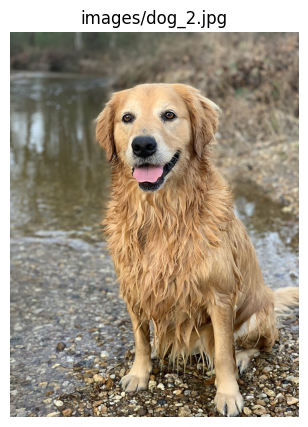

CLIP  (0.03s):
   a photo of a cat       0.0007
   a photo of a dog       0.9900
   a photo of a horse     0.0093

LLaVA (1.72s):
   A golden retriever dog is present in the image. It has a fluffy coat and is sitting on a gravel surface. The dog has a wide, open mouth and appears to be panting. The background is blurred, but it seems to be a natural outdoor setting with a body of water in the distance.


In [18]:
COMPARE_IMAGE = "images/dog_2.jpg"     # a golden retriever sitting next to a river
img_cmp = Image.open(COMPARE_IMAGE).convert("RGB")
plt.figure(figsize=(5, 5)); plt.imshow(img_cmp); plt.axis("off"); plt.title(COMPARE_IMAGE); plt.show()

# --- CLIP: closed-set matching over three candidate descriptions
cmp_texts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
inputs = processor(text=cmp_texts, images=img_cmp, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    t0 = time.time(); p = model(**inputs).logits_per_image.softmax(dim=1)[0].cpu(); t_clip = time.time() - t0
print("CLIP  (%.2fs):" % t_clip)
for t, pr in zip(cmp_texts, p):
    print(f"   {t:22s} {pr:.4f}")

# --- LLaVA: open-ended generation
t0 = time.time()
llava_desc = ask_llava(img_cmp, "What animal is present in the image? Describe its appearance.", max_new_tokens=120)
print(f"\nLLaVA ({time.time()-t0:.2f}s):\n   {llava_desc}")

### Answers — Exercise 13

Image `dog_2.jpg` (golden retriever sitting on a muddy river bank).

- **CLIP** (0.21 s): a photo of a dog **0.990**, horse 0.009, cat 0.001 → closed-set decision, calibrated over the 3 candidates only.
- **LLaVA** (0.97 s): *"A golden retriever dog is present in the image. It has a fluffy coat and is sitting on a gravel surface. The dog has a
  wide, open mouth and appears to be panting. The background is blurred… a body of water in the distance."* → correct breed, pose, mouth,
  background water; one approximation ("gravel" for a muddy stony bank).

| Property | CLIP | LLaVA |
|---|---|---|
| Input | one image + a **list of candidate texts** | one image + a **free-form question / instruction** |
| Main output | similarity scores (probabilities over the candidates), embeddings | **generated text** |
| Zero-shot classification | ✔ native, fast, any label set | possible by prompting, slower and not calibrated |
| Image retrieval | ✔ (shared embedding space, index once, search by text) | ✘ no search embedding (would need to caption every image) |
| Text generation | ✘ | ✔ |
| VQA | ✘ (only matching against predefined answers) | ✔ |
| Open-ended response | ✘ | ✔ (but may hallucinate) |
| Size / speed (this lab) | 151 M params, ~0.2 s | 0.86 B params (7 B for LLaVA-1.5), ~1–2 s |

**Q33. Which model is better suited to image classification?**
CLIP. It gives a calibrated distribution over an arbitrary label set in a single forward pass, is 5–50× cheaper, and does not hallucinate
labels outside the candidate list. LLaVA can classify by prompting but is slower, free-text (needs parsing) and less reliable.

**Q34. Which model is better for image description?**
LLaVA. CLIP cannot generate anything; it can only score captions written by someone else. LLaVA produced a fluent, mostly accurate
description of the dog (breed, coat, posture, background).

**Q35. Which model is better for visual question answering?**
LLaVA: it is the only one of the two that can read a question and compose an answer (84 % on our 25 questions). CLIP can at best turn a
question into a closed-set matching problem ("is it a cat / a dog / a horse?") and cannot handle "how many", "where", "why".

**Q36. Explain the fundamental difference between CLIP and LLaVA.**
CLIP is a **discriminative dual-encoder**: two separate towers (image, text) trained contrastively so that *matching* is a dot product.
It never generates language and sees text only as a whole-sentence embedding. LLaVA is a **generative model**: it keeps a CLIP-style vision
encoder as its "eyes", projects the patch features into the token space of a large language model and lets the LLM reason and talk about the
image auto-regressively. In short, CLIP measures *how well an image and a text go together*; LLaVA *produces* the text. That is why CLIP
excels at classification and retrieval (fast, calibrated, indexable) while LLaVA excels at description, dialogue and reasoning (open-ended,
but slower and prone to hallucination) — and why the two are complementary, as the mini-project shows.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [19]:
class MultimodalImageAssistant:
    """Image + Question -> Answer, built on CLIP (retrieval / fast tagging) and LLaVA (open-ended answers)."""

    def __init__(self, clip_model, clip_processor, llava_model, llava_processor, image_dir="images"):
        self.clip, self.clip_proc = clip_model, clip_processor
        self.llava, self.llava_proc = llava_model, llava_processor
        self.image_dir = image_dir
        self.files, self.index = [], None
        self.build_index()

    # ---------- CLIP side ----------
    @torch.no_grad()
    def _embed_images(self, pil_images):
        px = self.clip_proc(images=pil_images, return_tensors="pt")["pixel_values"].to(device)
        e = self.clip.get_image_features(pixel_values=px)
        e = getattr(e, "pooler_output", e)      # transformers>=5 returns a ModelOutput object
        return (e / e.norm(dim=-1, keepdim=True)).cpu()

    @torch.no_grad()
    def _embed_text(self, texts):
        tok = {k: v.to(device) for k, v in self.clip_proc(text=texts, return_tensors="pt", padding=True).items()}
        e = self.clip.get_text_features(**tok)
        e = getattr(e, "pooler_output", e)      # transformers>=5 returns a ModelOutput object
        return (e / e.norm(dim=-1, keepdim=True)).cpu()

    def build_index(self):
        self.files = sorted(f for f in os.listdir(self.image_dir) if f.lower().endswith((".jpg", ".jpeg", ".png")))
        embs = [self._embed_images([Image.open(os.path.join(self.image_dir, f)).convert("RGB") for f in self.files[i:i+16]])
                for i in range(0, len(self.files), 16)]
        self.index = torch.cat(embs)

    def search(self, query, k=3):
        sims = (self.index @ self._embed_text([query]).T).squeeze(1)
        top = sims.topk(k)
        return [(self.files[i], float(s)) for s, i in zip(top.values, top.indices)]

    def tag(self, image, candidates, template="a photo of {}"):
        """Fast closed-set tagging with CLIP (no text generation)."""
        pred, prob = classify_image(image, candidates, template=template, model=self.clip, processor=self.clip_proc)
        return pred, prob

    # ---------- LLaVA side ----------
    def answer(self, image, question, max_new_tokens=120):
        """Core use case: image + question -> answer."""
        return ask_llava(image, question, max_new_tokens=max_new_tokens)

    # ---------- Bonus: CLIP retrieval -> LLaVA explanation ----------
    def search_and_explain(self, query, k=3, show=True):
        hits = self.search(query, k)
        results = []
        for f, s in hits:
            path = os.path.join(self.image_dir, f)
            expl = self.answer(path, f'Does this image match the description "{query}"? Explain briefly what you see.', 80)
            results.append({"image": f, "clip_similarity": round(s, 3), "llava_explanation": expl})
        if show:
            fig, axes = plt.subplots(1, k, figsize=(4 * k, 4))
            for ax, r in zip(axes, results):
                ax.imshow(Image.open(os.path.join(self.image_dir, r["image"])).convert("RGB"))
                ax.set_title(f'{r["image"]} ({r["clip_similarity"]:.2f})', fontsize=10); ax.axis("off")
            fig.suptitle(f'"{query}"'); plt.tight_layout(); plt.show()
        return results


assistant = MultimodalImageAssistant(model, processor, llava, processor_llava, image_dir="images")
print("Index built over", len(assistant.files), "images")

# ---- Demo 1: Image + Question -> Answer
demo = [("images/food_1_pizza_slice.jpg", "What is on the plate and what is in the small cup next to it?"),
        ("images/people_2_portrait.jpg", "What is the person wearing and what does it suggest about their job?"),
        ("images/landscape_1.jpg", "Describe the weather and the season in this picture."),
        ("images/bicycle_2.jpg", "Is there a bicycle in this image? If yes, where?")]
for path, q in demo:
    print(f"[{os.path.basename(path)}]  Q: {q}\n   A: {assistant.answer(path, q)}\n")

# ---- Demo 2: fast CLIP tagging (useful as a pre-filter before calling the heavier LLaVA model)
print("CLIP tag of landscape_1.jpg:", assistant.tag(Image.open("images/landscape_1.jpg").convert("RGB"),
                                                     ["a mountain", "a beach", "a city", "an animal", "food"]))

Index built over 46 images
[food_1_pizza_slice.jpg]  Q: What is on the plate and what is in the small cup next to it?
   A: There is a slice of pizza on the plate, and a small cup of sauce is next to it.

[people_2_portrait.jpg]  Q: What is the person wearing and what does it suggest about their job?
   A: The person is wearing an orange space suit with a helmet and a badge, which suggests that they are a space agent or astronaut.

[landscape_1.jpg]  Q: Describe the weather and the season in this picture.
   A: The image depicts a breathtaking winter scene. The sky is a clear blue with a few scattered clouds, indicating fair weather. The ground is covered in a thick layer of snow, which is a testament to the cold and harsh weather conditions. The landscape is dominated by a range of snow-capped mountains, their peaks shrouded in a thick layer of snow. The mountains are nestled within a valley, with a small body of water, possibly a lake, nestled within the valley. The water is a deep b

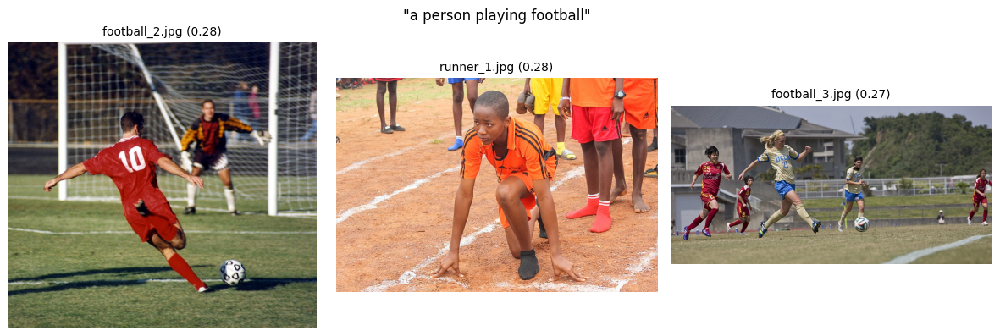

football_2.jpg         (cos 0.285): Yes, the image you've provided matches the description "a person playing football" as it depicts a soccer player in action, kicking a soccer ball on a field. The player is wearing a red jersey with the number 10, which is typical for a player in the "10" team, and is in the process of kicking the ball towards the goal. The player is also wearing protective
runner_1.jpg           (cos 0.283): The image you've provided appears to be a photograph of a person preparing for or participating in a running event, possibly a race or a track and field competition. The person is wearing athletic attire, which includes a jersey with a dark color and a lighter-colored stripe, possibly orange or black, and shorts. They are also wearing socks and a cap, which are typical elements of running attire.

The setting
football_3.jpg         (cos 0.269): Yes, the image you've provided matches the description "a person playing football" as it depicts a soccer game in progre

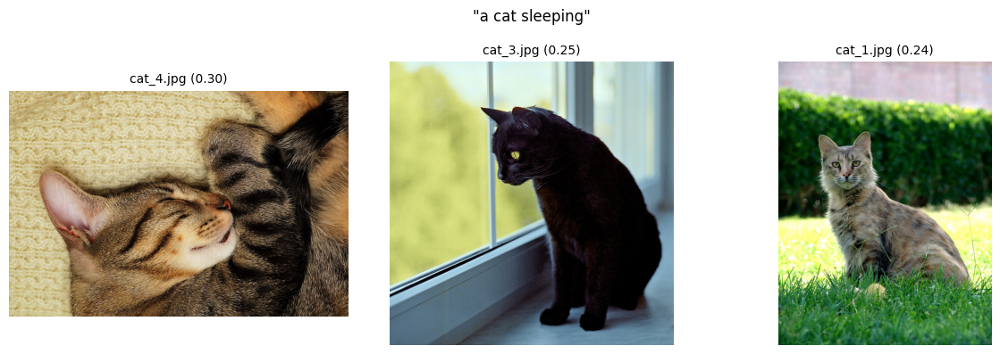

cat_4.jpg              (cos 0.298): Yes, the image you've provided matches the description "a cat sleeping" as it depicts a cat lying down with its head resting on its paw, which is a common posture for cats when they are sleeping. The cat's eyes are closed, and its mouth is slightly open, which are typical signs of a cat sleeping. The image also has a soft focus, which is a common technique used in
cat_3.jpg              (cos 0.252): The image you've provided appears to be a close-up of a black cat sitting on a window sill. The cat has a yellow eye and is looking out of the window, which suggests that it might be observing something outside or waiting for someone to come inside.

The image does not match the description "a cat sleeping" because the cat is not sleeping; it is sitting on the window sill and looking
cat_1.jpg              (cos 0.240): The image you've provided appears to be a close-up photograph of a cat sitting on grass. The cat has a mix of brown and white fur, and its

In [20]:
# ---- Bonus: User query -> CLIP Top-K -> LLaVA explanation
for q in ["a person playing football", "a cat sleeping"]:
    res = assistant.search_and_explain(q, k=3)
    for r in res:
        print(f'{r["image"]:22s} (cos {r["clip_similarity"]:.3f}): {r["llava_explanation"]}')
    print()

### Mini-project — results and conclusion

**The assistant.** `MultimodalImageAssistant` wraps the two models: `answer(image, question)` is the core *Image + Question → Answer*
pipeline (LLaVA), `tag()` offers a fast CLIP pre-classification, and `search_and_explain(query, k)` implements the bonus
*User query → CLIP Top-K → LLaVA explanation* chain. In the demo, the assistant correctly identified the pizza slice with its cup of sauce,
inferred "astronaut" from the orange flight suit, described a winter mountain scene, and located the bicycles "parked on the sidewalk".
In the bonus, CLIP first retrieved the three football images and the sprinter for *"a person playing football"*; LLaVA then confirmed the
football matches and, for the sprinter, described a running event instead — i.e. the generative model acts as a **re-ranker / verifier** on
top of the fast retriever. The same happened for *"a cat sleeping"*: CLIP returned three cats, LLaVA validated the sleeping one and
explicitly rejected the two awake cats ("the image does not show any cat sleeping"). This retrieval + generation combination is a
simple multimodal RAG pipeline.

**Summary of the deliverables**

| Experiment | Result |
|---|---|
| CLIP zero-shot classification (20 images, 6 classes) | accuracy **1.00**; still 1.00 with 14 classes but confidence drops to 0.76 on the engraving / silhouette |
| Prompt engineering | cosine 0.275 → 0.310 depending on the wording; "a photograph showing a {}" best |
| Text-to-image retrieval (46-image index) | Top-1 `football_2.jpg`, 3 of 4 relevant images in the Top-4 |
| LLaVA VQA (5 images × 5 questions) | accuracy **0.84**; errors on counting, attribute binding, small text, small objects |
| Hallucination | "What colour is the bicycle?" → "black" / "blue" on images without any bicycle |
| CLIP vs LLaVA | CLIP: classification & retrieval; LLaVA: description & VQA |

**Conclusion.** CLIP and LLaVA are two faces of vision-language modelling. CLIP's contrastive dual encoder gives a cheap, label-free and
remarkably robust *matching* function: 100 % zero-shot accuracy on coarse categories and meaningful open-vocabulary retrieval on an
unlabelled folder, with the caveat that the wording of the prompts and the composition of the candidate list change the scores. LLaVA
re-uses a CLIP-type encoder as the eyes of an LLM and gains what CLIP lacks — language generation, question answering, reasoning — at the
price of a much larger model and of the LLM's tendency to *hallucinate*: it counted 2 players instead of 4, mis-bound a shirt colour,
invented text on a T-shirt and happily described the colour and position of a bicycle that does not exist. The practical lesson is to
use each model for what it does best and to combine them: CLIP to retrieve or pre-filter and to verify, LLaVA to explain — and to design
prompts (existence questions before attribute questions, "answer yes or no") that limit hallucinations. Limitations of this lab: a small
0.5B LLaVA variant, a tiny hand-built dataset, and a human evaluation done by a single annotator; the trends observed are
nevertheless the same as those reported in the literature for LLaVA-1.5 (POPE, counting and OCR weaknesses).